# GLoRIA on RSNA Pneumonia dataset

In [1]:
# Imports & environment configurations
import importlib.util
import json
import subprocess
import sys
import time
from pathlib import Path

if importlib.util.find_spec('pydicom') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pydicom'], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
import torch
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    precision_recall_curve, precision_recall_fscore_support,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms

SEED = 42
MAX_EPOCHS = 50
PATIENCE = 10
IMAGE_BATCH_SIZE = 64
HEAD_BATCH_SIZE = 64
INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
RESULTS = WORK / 'gloria_rsna_results'
RESULTS.mkdir(parents=True, exist_ok=True)
run_start = time.perf_counter()

if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle Notebook settings.')
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
print('Using:', torch.cuda.get_device_name(0), 'and', torch.cuda.get_device_name(1))

Using: Tesla T4 and Tesla T4


In [2]:
# Find RSNA labels, DICOM images, and the official GLoRIA checkpoint
data_roots = [
    path.parent for path in INPUT.rglob('stage_2_train_labels.csv')
    if (path.parent / 'stage_2_train_images').is_dir()
]
checkpoints = list(INPUT.rglob('chexpert_resnet50.ckpt'))
if len(data_roots) != 1:
    raise FileNotFoundError('Attach one RSNA Pneumonia Detection Challenge input with stage_2_train_labels.csv and stage_2_train_images/.')
if len(checkpoints) != 1:
    raise FileNotFoundError('Attach the official chexpert_resnet50.ckpt checkpoint as a Kaggle input.')

data_root = data_roots[0]
image_root = data_root / 'stage_2_train_images'
checkpoint_path = checkpoints[0]
repo = WORK / 'gloria_official'
if not (repo / 'gloria/models/cnn_backbones.py').is_file():
    subprocess.run(
        ['git', 'clone', '--depth', '1', 'https://github.com/marshuang80/gloria.git', str(repo)],
        check=True,
    )
repo_commit = subprocess.check_output(
    ['git', '-C', str(repo), 'rev-parse', 'HEAD'], text=True
).strip()
print('RSNA data:', data_root)
print('GLoRIA checkpoint:', checkpoint_path)
print('Official code commit:', repo_commit[:12])

Cloning into '/kaggle/working/gloria_official'...


RSNA data: /kaggle/input/competitions/rsna-pneumonia-detection-challenge
GLoRIA checkpoint: /kaggle/input/datasets/shadril238/gloria-chexpert-checkpoint/chexpert_resnet50.ckpt
Official code commit: 416466af1036


In [3]:
# Aggregate duplicate box rows and create stratified 70/15/15 image splits
raw_labels = pd.read_csv(data_root / 'stage_2_train_labels.csv', usecols=['patientId', 'Target'])
images = raw_labels.groupby('patientId', as_index=False)['Target'].max()
images['Target'] = images['Target'].astype(np.float32)
images['image_path'] = images['patientId'].map(
    lambda patient_id: image_root / f'{patient_id}.dcm'
)
missing = images.loc[~images['image_path'].map(Path.is_file), 'patientId']
if len(missing):
    raise FileNotFoundError(f'{len(missing)} labelled DICOM images are missing; first ID: {missing.iloc[0]}')

train_df, holdout_df = train_test_split(
    images, test_size=0.30, random_state=SEED, stratify=images['Target']
)
val_df, test_df = train_test_split(
    holdout_df, test_size=0.50, random_state=SEED, stratify=holdout_df['Target']
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
for name, frame in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f'{name}: {len(frame):,} images | {int(frame.Target.sum()):,} positive | {len(frame) - int(frame.Target.sum()):,} negative')

Train: 18,678 images | 4,208 positive | 14,470 negative
Validation: 4,003 images | 902 positive | 3,101 negative
Test: 4,003 images | 902 positive | 3,101 negative


In [4]:
# Decode DICOM images and prepare 256-to-224 normalized model inputs
transform = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

class RSNAImages(Dataset):
    def __init__(self, frame):
        self.paths = frame['image_path'].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        dicom = pydicom.dcmread(self.paths[index])
        pixels = dicom.pixel_array.astype(np.float32)
        pixels = np.clip(pixels * (255.0 / max(float(pixels.max()), 1.0)), 0, 255).astype(np.uint8)
        if dicom.get('PhotometricInterpretation', '') == 'MONOCHROME1':
            pixels = 255 - pixels
        image = ImageOps.pad(
            Image.fromarray(pixels).convert('L'), (256, 256),
            method=Image.Resampling.BILINEAR, color=0,
        ).convert('RGB')
        return transform(image)

def image_loader(frame):
    return DataLoader(
        RSNAImages(frame), batch_size=IMAGE_BATCH_SIZE,
        shuffle=False, num_workers=4, pin_memory=True,
    )

print('DICOM image preparation ready.')

DICOM image preparation ready.


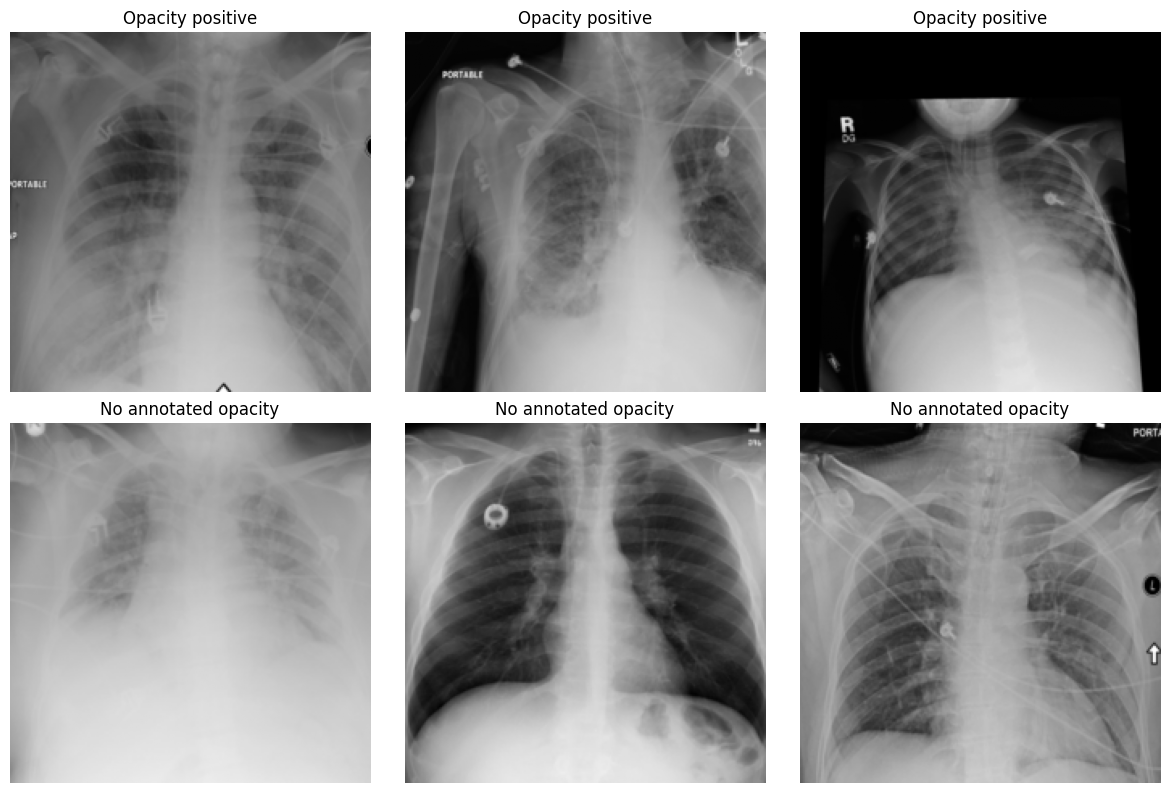

In [5]:
# Display three positive and three negative training images
positive = train_df.loc[train_df['Target'] == 1].sample(3, random_state=SEED)
negative = train_df.loc[train_df['Target'] == 0].sample(3, random_state=SEED)
sample_frame = pd.concat([positive, negative]).reset_index(drop=True)
sample_images = RSNAImages(sample_frame)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for index, ax in enumerate(axes.flat):
    image = sample_images[index][0].numpy() * 0.5 + 0.5
    ax.imshow(image, cmap='gray', vmin=0, vmax=1)
    ax.set_title('Opacity positive' if sample_frame.iloc[index]['Target'] == 1 else 'No annotated opacity')
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=180)
plt.show()
plt.close(fig)

In [6]:
# Load the official pretrained GLoRIA ResNet-50 image encoder on both T4 GPUs
source = repo / 'gloria/models/cnn_backbones.py'
spec = importlib.util.spec_from_file_location('gloria_backbones', source)
official = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official)
backbone, feature_size, _ = official.resnet_50(pretrained=False)

weights_file = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
checkpoint_weights = weights_file.get('state_dict', weights_file)
model_weights = backbone.state_dict()
weights = {}
for name, value in checkpoint_weights.items():
    marker = 'img_encoder.model.'
    if marker in name:
        key = name.split(marker, 1)[1]
        if key in model_weights and value.shape == model_weights[key].shape:
            weights[key] = value
if len(weights) < 250:
    raise ValueError('The attached checkpoint is not the official GLoRIA ResNet-50 checkpoint.')
backbone.load_state_dict(weights, strict=True)
del weights_file, checkpoint_weights, model_weights, weights
backbone.eval()

class GLoRIAFeatures(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, images):
        images = nn.functional.interpolate(
            images, size=(299, 299), mode='bilinear', align_corners=True,
        )
        return self.model(images)

encoder = nn.DataParallel(GLoRIAFeatures(backbone), device_ids=[0, 1]).cuda().eval()
print('Loaded GLoRIA image encoder with', feature_size, 'features per image.')

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Loaded GLoRIA image encoder with 2048 features per image.


In [7]:
# Extract frozen GLoRIA features from each data split once
def extract_features(frame):
    vectors = np.empty((len(frame), feature_size), dtype=np.float16)
    offset = 0
    with torch.inference_mode():
        for images in image_loader(frame):
            with torch.autocast('cuda', dtype=torch.float16):
                batch = encoder(images.cuda(non_blocking=True))
            count = len(batch)
            vectors[offset:offset + count] = batch.cpu().numpy().astype(np.float16)
            offset += count
    return vectors

feature_start = time.perf_counter()
train_x = extract_features(train_df)
val_x = extract_features(val_df)
test_x = extract_features(test_df)
feature_minutes = (time.perf_counter() - feature_start) / 60
train_y = train_df['Target'].to_numpy(dtype=np.float32).reshape(-1, 1)
val_y = val_df['Target'].to_numpy(dtype=np.float32).reshape(-1, 1)
test_y = test_df['Target'].to_numpy(dtype=np.float32).reshape(-1, 1)
print(f'Feature extraction finished in {feature_minutes:.1f} minutes.')

Feature extraction finished in 2.9 minutes.


In [8]:
# Train one binary linear head for up to 50 epochs with validation early stopping
def head_loader(features, labels, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(features.astype(np.float32)), torch.from_numpy(labels),
    )
    return DataLoader(dataset, batch_size=HEAD_BATCH_SIZE, shuffle=shuffle)

train_loader = head_loader(train_x, train_y, shuffle=True)
val_loader = head_loader(val_x, val_y)
head = nn.Linear(feature_size, 1).cuda()
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(head.parameters(), lr=5e-4, weight_decay=1e-6)
history = []
best_val_loss = float('inf')
best_epoch = 0
epochs_without_improvement = 0
training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    head.train()
    train_loss = 0.0
    for features, labels in train_loader:
        features, labels = features.cuda(), labels.cuda()
        optimizer.zero_grad()
        loss = loss_fn(head(features), labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(features)

    head.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for features, labels in val_loader:
            features, labels = features.cuda(), labels.cuda()
            val_loss += loss_fn(head(features), labels).item() * len(features)

    train_loss /= len(train_df)
    val_loss /= len(val_df)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss})
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(head.state_dict(), RESULTS / 'best_head.pt')
    else:
        epochs_without_improvement += 1
    print(f'Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f}')
    if epochs_without_improvement >= PATIENCE:
        print(f'Early stopping at epoch {epoch}.')
        break

training_minutes = (time.perf_counter() - training_start) / 60
torch.save(head.state_dict(), RESULTS / 'last_head.pt')
head.load_state_dict(torch.load(RESULTS / 'best_head.pt', map_location='cuda', weights_only=True))
head.eval()
print(f'Best epoch: {best_epoch} | head training: {training_minutes:.1f} minutes')

Epoch 01/50 | train loss 0.3841 | val loss 0.3561
Epoch 02/50 | train loss 0.3554 | val loss 0.3479
Epoch 03/50 | train loss 0.3532 | val loss 0.3465
Epoch 04/50 | train loss 0.3508 | val loss 0.3460
Epoch 05/50 | train loss 0.3484 | val loss 0.3536
Epoch 06/50 | train loss 0.3483 | val loss 0.3459
Epoch 07/50 | train loss 0.3488 | val loss 0.3466
Epoch 08/50 | train loss 0.3508 | val loss 0.3451
Epoch 09/50 | train loss 0.3490 | val loss 0.3499
Epoch 10/50 | train loss 0.3466 | val loss 0.3462
Epoch 11/50 | train loss 0.3465 | val loss 0.3490
Epoch 12/50 | train loss 0.3450 | val loss 0.3448
Epoch 13/50 | train loss 0.3460 | val loss 0.3454
Epoch 14/50 | train loss 0.3448 | val loss 0.3482
Epoch 15/50 | train loss 0.3445 | val loss 0.3482
Epoch 16/50 | train loss 0.3413 | val loss 0.3435
Epoch 17/50 | train loss 0.3423 | val loss 0.3434
Epoch 18/50 | train loss 0.3410 | val loss 0.3449
Epoch 19/50 | train loss 0.3413 | val loss 0.3510
Epoch 20/50 | train loss 0.3395 | val loss 0.3441


In [9]:
# Select a threshold on validation data and evaluate the held-out RSNA test split once
def predict(features):
    results = []
    with torch.inference_mode():
        for start in range(0, len(features), 4096):
            batch = torch.from_numpy(features[start:start + 4096].astype(np.float32)).cuda()
            results.append(head(batch).sigmoid().cpu().numpy().ravel())
    return np.concatenate(results)

val_probs = predict(val_x)
choices = np.linspace(0.05, 0.95, 181)
val_f1 = [
    precision_recall_fscore_support(
        val_y.ravel().astype(int), val_probs >= threshold,
        average='binary', zero_division=0,
    )[2]
    for threshold in choices
]
threshold = float(choices[np.argmax(val_f1)])

test_start = time.perf_counter()
test_probs = predict(test_x)
truth = test_y.ravel().astype(int)
predicted = (test_probs >= threshold).astype(int)
precision, recall, f1, _ = precision_recall_fscore_support(
    truth, predicted, average='binary', zero_division=0,
)
metrics = {
    'AUROC': float(roc_auc_score(truth, test_probs)),
    'AUPRC': float(average_precision_score(truth, test_probs)),
    'accuracy': float(accuracy_score(truth, predicted)),
    'precision': float(precision),
    'recall': float(recall),
    'F1': float(f1),
    'threshold': threshold,
}
test_seconds = time.perf_counter() - test_start
predictions = test_df[['patientId', 'Target']].copy()
predictions['probability'] = test_probs
predictions['prediction'] = predicted
print(pd.Series(metrics).round(3).to_string())

AUROC        0.890
AUPRC        0.715
accuracy     0.821
precision    0.578
recall       0.752
F1           0.654
threshold    0.310


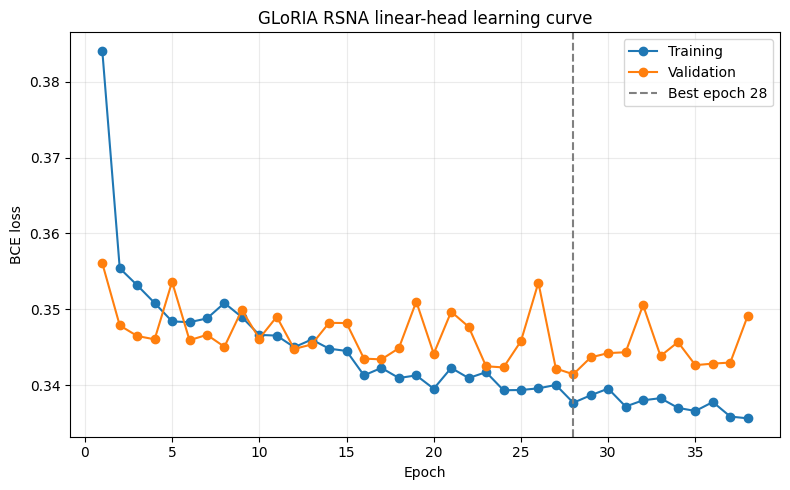

In [10]:
# Plot training and validation loss by epoch
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Training')
ax.plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation')
ax.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch {best_epoch}')
ax.set(title='GLoRIA RSNA linear-head learning curve', xlabel='Epoch', ylabel='BCE loss')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'learning_curve.png', dpi=180)
plt.show()
plt.close(fig)

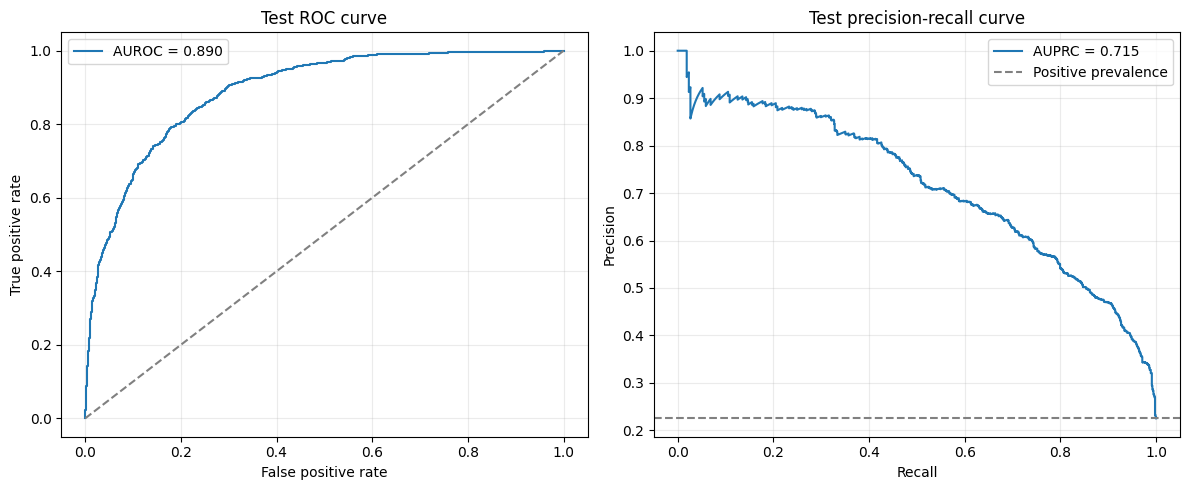

In [11]:
# Plot held-out test ROC and precision-recall curves
fpr, tpr, _ = roc_curve(truth, test_probs)
pr_precision, pr_recall, _ = precision_recall_curve(truth, test_probs)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f'AUROC = {metrics["AUROC"]:.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Test ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend()
axes[1].plot(pr_recall, pr_precision, label=f'AUPRC = {metrics["AUPRC"]:.3f}')
axes[1].axhline(truth.mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[1].set(title='Test precision-recall curve', xlabel='Recall', ylabel='Precision')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / 'test_roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)

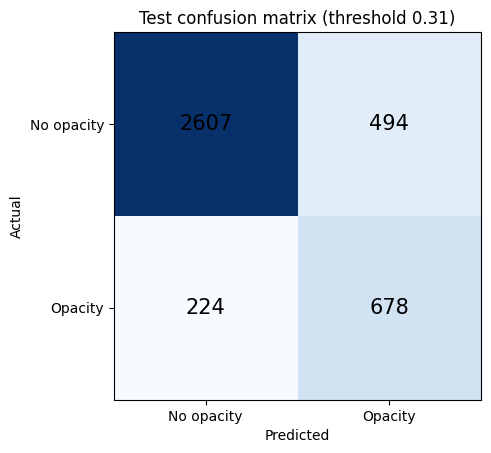

In [12]:
# Plot the held-out test confusion matrix at the validation-selected threshold
matrix = confusion_matrix(truth, predicted, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(matrix, cmap='Blues')
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(matrix[row, col]), ha='center', va='center', fontsize=15)
ax.set(
    title=f'Test confusion matrix (threshold {threshold:.2f})',
    xlabel='Predicted', ylabel='Actual',
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=['No opacity', 'Opacity'],
    yticklabels=['No opacity', 'Opacity'],
)
fig.tight_layout()
fig.savefig(RESULTS / 'test_confusion_matrix.png', dpi=180)
plt.show()
plt.close(fig)

In [13]:
# Save metrics, patient splits, predictions, run settings, and timing
history_df.to_csv(RESULTS / 'history.csv', index=False)
pd.Series(metrics, name='value').to_csv(RESULTS / 'test_metrics.csv')
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    frame[['patientId', 'Target']].to_csv(RESULTS / f'{name}_split.csv', index=False)

summary = {
    'model': 'GLoRIA frozen CheXpert-pretrained image encoder with binary linear head',
    'dataset': 'RSNA Pneumonia Detection Challenge, stage 2 labelled training images',
    'target': 'radiographic opacity suspicious for pneumonia',
    'split': 'stratified 70/15/15 image split; one image per patientId',
    'seed': SEED,
    'max_epochs': MAX_EPOCHS,
    'early_stopping_patience': PATIENCE,
    'epochs_run': len(history),
    'best_epoch': best_epoch,
    'checkpoint': str(checkpoint_path),
    'official_repo_commit': repo_commit,
    'torch_version': torch.__version__,
    'pydicom_version': pydicom.__version__,
    'gpu': [torch.cuda.get_device_name(i) for i in range(2)],
    'feature_extraction_minutes': feature_minutes,
    'head_training_minutes': training_minutes,
    'test_evaluation_seconds': test_seconds,
    'total_run_minutes': (time.perf_counter() - run_start) / 60,
}
(RESULTS / 'run_info.json').write_text(json.dumps(summary, indent=2))
print(f'Feature extraction: {feature_minutes:.1f} min')
print(f'Head training:      {training_minutes:.1f} min')
print(f'Total run:          {summary["total_run_minutes"]:.1f} min')
print('Saved files to:', RESULTS)

Feature extraction: 2.9 min
Head training:      0.3 min
Total run:          5.4 min
Saved files to: /kaggle/working/gloria_rsna_results
